# Field Shift · Phase 1 — Training (1998–2017)

XGBoost models for Lambayeque, Peru, trained **only** on 1998–2017. Validation (2018–2022) and Testing (2023–2026) are
reserved: no row from those years is used to fit, tune or choose anything in this notebook. Every number reported here is
an **internal training diagnostic**, not the expected accuracy on new years.

Runs locally (Jupyter) with `ml/.venv`. Set `FIELDSHIFT_RAW_DIR` to the team folder *Datos para proyecto Nasa*.
Method, irregularities found and the criteria for the next phases: `docs/ML_PHASE1_TRAINING.md`.

## 1. Environment, seeds and library versions

In [1]:
import os, sys, json, platform, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, xgboost as xgb, matplotlib
import matplotlib.pyplot as plt

ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from fs_ml import data as D, features as F, evaluate as E

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160, "display.max_columns", 30)

SPLITS = {"training": (1998, 2017), "validation": (2018, 2022), "testing": (2023, 2026)}
INTERNAL = {"fit": (1998, 2015), "early_stopping": (2016, 2017)}   # both inside Training
YEARS = SPLITS["training"]

OUT_DATA = ML_DIR / "data" / "processed"
ART = ML_DIR / "artifacts" / "phase1_training"
OUT_DATA.mkdir(parents=True, exist_ok=True); ART.mkdir(parents=True, exist_ok=True)

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit_learn": sklearn.__version__, "xgboost": xgb.__version__,
            "matplotlib": matplotlib.__version__, "platform": platform.platform()}
VERSIONS

{'python': '3.14.6',
 'numpy': '2.5.4',
 'pandas': '3.1.1',
 'scipy': '1.18.1',
 'scikit_learn': '1.9.1',
 'xgboost': '3.4.1',
 'matplotlib': '3.11.2',
 'platform': 'Linux-7.0.0-42-generic-x86_64-with-glibc2.43'}

## 2. Inventory of the existing datasets

In [2]:
files = []
for key, rel in D.RAW_FILES.items():
    p = D.raw_path(key)
    files.append({"key": key, "file": rel, "MB": round(p.stat().st_size / 1e6, 1), "sha256": D.sha256(p)})
FILES = pd.DataFrame(files)
FILES[["key", "file", "MB"]]

,key,file,MB
0,gee_monthly,Hídrico/GEE_2km_Clima_Humedad_Mensual_1998_01_...,498.8
1,gee_quarterly,Hídrico/GEE_2km_Veg_Salinidad_Trimestral_1998_...,72.0
2,gee_s2_scenes,Hídrico/Lambayeque_Grilla_2km.csv,69.7
3,power_t2m,Clima y metereología/Temperature at 2 Meters_M...,0.0
4,power_rh2m,Clima y metereología/Relative Humidity at 2 Me...,0.0
5,power_ws2m,Clima y metereología/Wind Speed at 2 Meters_Mo...,0.0
6,power_allsky,Clima y metereología/All Sky Surface Shortwave...,0.0
7,gaez_nutrient_low,Suelos/Nutrient Availability low.json,1.9
8,gaez_oxygen_high,Suelos/Oxygen Availability High.json,1.9
9,gaez_oxygen_low,Suelos/Oxygen Availability Low.json,1.9


### 2.1 GEE monthly 2 km table (CHIRPS + ERA5-Land) — only 1998–2017 is loaded

In [3]:
monthly, info_m = D.load_gee_monthly(YEARS)
print(info_m)
print("cells:", monthly.cell_id.nunique(), "| months:", monthly.date.nunique(), monthly.date.min().date(), "->", monthly.date.max().date())
print("duplicate (cell, month):", int(monthly.duplicated(["cell_id", "date"]).sum()))
display(monthly.head(3)); display(monthly.tail(3))
display(monthly.describe().T.round(3))
monthly.isna().sum()

{'rows_total': 1089554, 'rows_kept': 755760, 'rows_outside_window_not_used': 333794, 'index_prefix_matches_month': True}
cells: 3149 | months: 240 1998-01-01 -> 2017-12-01
duplicate (cell, month): 0


,cell_id,date,rain_mm,t2m_c,pet_mm,sm_surface_m3m3,sm_root_m3m3
0,"-4400,-313",1998-01-01,60.723706,18.075682,200.152352,0.393661,0.401712
1,"-4400,-313",1998-02-01,171.015173,18.323037,152.990982,0.415479,0.412361
2,"-4400,-313",1998-03-01,183.757465,17.970655,161.058739,0.458338,0.459310


,cell_id,date,rain_mm,t2m_c,pet_mm,sm_surface_m3m3,sm_root_m3m3
755757,"-4491,-323",2017-10-01,1.916424e-09,20.707496,196.242385,0.026930,0.164846
755758,"-4491,-323",2017-11-01,2.152642e-14,20.531964,177.529909,0.026866,0.161923
755759,"-4491,-323",2017-12-01,2.355254e-14,23.044526,194.375366,0.027580,0.159657


,count,mean,min,25%,50%,75%,max,std
date,755760,2007-12-16 11:00:00,1998-01-01 00:00:00,2002-12-24 06:00:00,2007-12-16 12:00:00,2012-12-08 18:00:00,2017-12-01 00:00:00,NaN
rain_mm,755760.0,17.091648,0.0,0.390153,3.450312,18.30251,467.475513,32.505042
t2m_c,750240.0,20.148913,8.846089,18.101301,20.164595,22.448916,28.022225,3.321999
pet_mm,750240.0,259.229391,92.336915,181.21931,214.30748,309.380427,832.851753,113.788401
sm_surface_m3m3,750240.0,0.181889,0.000022,0.061126,0.15873,0.281321,0.492221,0.127569
sm_root_m3m3,750240.0,0.218981,0.053757,0.132147,0.222334,0.2861,0.504655,0.103839


cell_id               0
date                  0
rain_mm               0
t2m_c              5520
pet_mm             5520
sm_surface_m3m3    5520
sm_root_m3m3       5520
dtype: int64

In [4]:
era5_missing = monthly.groupby("cell_id")["t2m_c"].apply(lambda s: s.isna().all())
print("cells with no ERA5-Land value in any month:", int(era5_missing.sum()), "->", sorted(era5_missing[era5_missing].index)[:6], "...")
print("largest gap between id-derived and polygon centers (deg):", D.check_cell_geometry())

cells with no ERA5-Land value in any month: 23 -> ['-4435,-393', '-4435,-394', '-4436,-393', '-4436,-394', '-4437,-393', '-4437,-394'] ...
largest gap between id-derived and polygon centers (deg): 2.842170943040401e-14


### 2.2 GEE quarterly 2 km vegetation table (NDVI, NDSI_Salinidad) — only 1998–2017

In [5]:
veg, info_q = D.load_gee_quarterly(YEARS)
print(info_q)
print("cells:", veg.cell_id.nunique(), "| duplicate (cell, quarter):", int(veg.duplicated(["cell_id", "year", "quarter"]).sum()))
display(veg.describe().T.round(3))
n_cells_veg = veg.cell_id.nunique()
cov = veg.groupby(["year", "quarter"]).size().unstack("quarter").reindex(range(YEARS[0], YEARS[1] + 1))
print(f"Cells with an NDVI value per quarter (of {n_cells_veg}); empty = no image at all:")
cov

{'rows_total': 181580, 'rows_kept': 91224, 'rows_outside_window_not_used': 90356}
cells: 2585 | duplicate (cell, quarter): 0


,count,mean,std,min,25%,50%,75%,max
year,91224.0,2008.379,7.379,1998.000,2000.000,2013.000,2015.000,2017.000
quarter,91224.0,2.552,1.085,1.000,2.000,3.000,3.000,4.000
ndvi,91224.0,0.360,0.195,-0.716,0.205,0.335,0.497,0.948
ndsi_salinidad,91222.0,0.348,0.144,-0.955,0.261,0.353,0.443,0.908


Cells with an NDVI value per quarter (of 2585); empty = no image at all:


quarter,1,2,3,4
year,,,,
1998,2117.0,1917.0,2571.0,2471.0
1999,2427.0,2217.0,2269.0,2489.0
2000,2471.0,940.0,2298.0,2538.0
2001,2128.0,2061.0,325.0,293.0
2002,280.0,NaN,NaN,NaN
2003,NaN,NaN,347.0,349.0
2004,318.0,295.0,1805.0,342.0
2005,269.0,306.0,393.0,258.0
2006,1.0,309.0,342.0,347.0


In [6]:
print("quarters with any data:", int(cov.notna().sum().sum()), "of", cov.size)
print("NDVI vs NDSI_Salinidad Pearson r (1998-2017):", round(veg[["ndvi", "ndsi_salinidad"]].corr().iloc[0, 1], 3))
print("NDVI < 0 rows:", int((veg.ndvi < 0).sum()), "| NDSI missing:", int(veg.ndsi_salinidad.isna().sum()))

quarters with any data: 62 of 80
NDVI vs NDSI_Salinidad Pearson r (1998-2017): 0.816
NDVI < 0 rows: 342 | NDSI missing: 2


### 2.3 `Lambayeque_Grilla_2km.csv` — Sentinel-2 scenes (only the dates are read)

In [7]:
s2_dates = pd.read_csv(D.raw_path("gee_s2_scenes"), usecols=["fecha"])["fecha"]
print("rows:", len(s2_dates), "| dates:", s2_dates.min(), "->", s2_dates.max())
print("All rows fall in the Testing years (2023-2026): this file is NOT used in Phase 1.")

rows: 167087 | dates: 2023-01-01 -> 2024-12-29
All rows fall in the Testing years (2023-2026): this file is NOT used in Phase 1.


### 2.4 NASA POWER regional monthly CSVs (1998–2017)

In [8]:
power, power_info = {}, {}
for key in ["power_t2m", "power_rh2m", "power_ws2m", "power_allsky"]:
    power[key], power_info[key] = D.load_power(key, YEARS)
    i = power_info[key]; col = power[key].columns[-1]
    pts = power[key][["power_lat", "power_lon"]].drop_duplicates()
    print(f"{key:13s} {i['parameter']:18s} wide rows={i['rows_wide']} dup={i['duplicate_rows']} -999={i['missing_-999']} "
          f"points={len(pts)} lat {pts.power_lat.min()}..{pts.power_lat.max()} lon {pts.power_lon.min()}..{pts.power_lon.max()} "
          f"range {power[key][col].min():.2f}..{power[key][col].max():.2f}")
print(power_info["power_rh2m"]["header"])

power_t2m     T2M                wide rows=400 dup=0 -999=0 points=20 lat -7.5..-5.5 lon -80.625..-78.75 range 12.13..29.35
power_rh2m    RH2M               wide rows=400 dup=0 -999=0 points=20 lat -7.5..-5.5 lon -80.625..-78.75 range 46.42..97.13
power_ws2m    WS2M               wide rows=400 dup=0 -999=0 points=20 lat -7.5..-5.5 lon -80.625..-78.75 range 1.02..6.02
power_allsky  ALLSKY_SFC_SW_DWN  wide rows=120 dup=0 -999=0 points=6 lat -7.5..-5.5 lon -80.5..-79.5 range 9.20..25.80
-BEGIN HEADER-
NASA/POWER Source Native Resolution Monthly and Annual 
Dates (month/day/year): 01/01/1998 through 12/31/2017 in LST
Location: Regional 
Elevation from MERRA-2: Average for 0.5 x 0.625 degree lat/lon region = na meters
The value for missing source data that cannot be computed or is outside of the sources availability range: -999 
Parameter(s): 
RH2M     MERRA-2 Relative Humidity at 2 Meters (%) 
-END HEADER-


### 2.5 FAO GAEZ soil layers (JSON, 5′ ≈ 9 km)

In [9]:
gaez, gaez_meta = {}, {}
for key in [k for k in D.RAW_FILES if k.startswith("gaez_")]:
    gaez[key], gaez_meta[key] = D.load_gaez(key)
LAMB = dict(lat=(-7.25, -5.35), lon=(-80.75, -78.95))
rows = []
for key, px in gaez.items():
    box = px[px.latitude.between(*LAMB["lat"]) & px.longitude.between(*LAMB["lon"])]
    rows.append({"layer": key, "pixels_peru": len(px), "pixels_lambayeque": len(box),
                 "classes_lambayeque": box.value.value_counts().sort_index().to_dict()})
display(pd.DataFrame(rows))
def identical(a, b):
    j = gaez[a].set_index(["row", "col"]).value.to_frame("a").join(gaez[b].set_index(["row", "col"]).value.to_frame("b"), how="inner")
    return float((j.a == j.b).mean())
for a, b in [("gaez_lime_gypsum_high", "gaez_lime_gypsum_low"), ("gaez_salinity_high", "gaez_salinity_low"),
             ("gaez_rooting_high", "gaez_rooting_low"), ("gaez_oxygen_high", "gaez_oxygen_low")]:
    print(f"{a} vs {b}: identical pixels = {identical(a, b):.4f}")

,layer,pixels_peru,pixels_lambayeque,classes_lambayeque
0,gaez_nutrient_low,15352,412,"{5: 2, 6: 145, 7: 43, 8: 58, 9: 160, 10: 4}"
1,gaez_oxygen_high,15352,412,{10: 412}
2,gaez_oxygen_low,15352,412,"{7: 2, 8: 5, 9: 8, 10: 397}"
3,gaez_lime_gypsum_high,15352,412,"{9: 12, 10: 400}"
4,gaez_lime_gypsum_low,15352,412,"{9: 12, 10: 400}"
5,gaez_salinity_high,15352,412,"{6: 1, 7: 7, 8: 77, 9: 64, 10: 263}"
6,gaez_salinity_low,15352,412,"{6: 1, 7: 7, 8: 77, 9: 64, 10: 263}"
7,gaez_rooting_high,15352,412,"{3: 29, 4: 20, 5: 10, 6: 22, 7: 21, 8: 29, 9: ..."
8,gaez_rooting_low,15352,412,"{3: 29, 4: 20, 5: 10, 6: 22, 7: 21, 8: 29, 9: ..."


gaez_lime_gypsum_high vs gaez_lime_gypsum_low: identical pixels = 1.0000
gaez_salinity_high vs gaez_salinity_low: identical pixels = 1.0000
gaez_rooting_high vs gaez_rooting_low: identical pixels = 1.0000
gaez_oxygen_high vs gaez_oxygen_low: identical pixels = 0.7269


### 2.6 MIDAGRI producer register exports (Excel) — inspected, not trainable

In [10]:
import glob, hashlib
mid_dir = os.environ.get("FIELDSHIFT_MIDAGRI_DIR")
if mid_dir:
    groups = {}
    for f in sorted(glob.glob(os.path.join(mid_dir, "*.xlsx"))):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            t = pd.read_excel(f)
        if list(t.columns[:4]) != ["Ver Mapa", "Departamento", "Provincia", "Distrito"]:
            continue
        h = hashlib.sha256(pd.util.hash_pandas_object(t, index=False).values.tobytes()).hexdigest()[:12]
        groups.setdefault(h, {"files": [], "rows": len(t), "province": t["Provincia"].unique().tolist(), "columns": list(t.columns),
                              "missing_crop": int(t.iloc[:, -1].isna().sum())})["files"].append(os.path.basename(f))
    for h, g in groups.items():
        print(h, g["province"], "rows:", g["rows"], "| missing crop:", g["missing_crop"], "| identical files:", len(g["files"]))
    print("columns:", next(iter(groups.values()))["columns"])
else:
    print("FIELDSHIFT_MIDAGRI_DIR not set: see docs/ML_PHASE1_TRAINING.md for the inspection result.")

cb4891ca2207 ['Chiclayo'] rows: 2000 | missing crop: 78 | identical files: 5
437fb9616bfb ['Lambayeque'] rows: 2000 | missing crop: 192 | identical files: 7
4ef18b1a3d1c ['Ferreñafe'] rows: 2000 | missing crop: 145 | identical files: 6
columns: ['Ver Mapa', 'Departamento', 'Provincia', 'Distrito', 'Centro Poblado', 'Régimen de tenencia predominante', 'Cultivo principal del distrito']


## 3. Trainable targets and blocked targets

| Target column | Type | Unit | Reference data | Decision |
|---|---|---|---|---|
| `sm_root_m3m3` (ERA5-Land `volumetric_soil_water_layer_3`, 28–100 cm), month *t* | Regression | m³/m³ | ERA5-Land reanalysis, ~9 km, complete 1998–2017 | **Trained** |
| `ndvi`, quarter *q* | Regression | index (−1…1) | Satellite NDVI composite per 2 km cell, 62 of 80 quarters | **Trained** |
| `ndsi_salinidad` | Regression | index | Same composite | **Not trained**: formula and meaning not documented, and it rises with NDVI (r ≈ 0.82), unlike a salinity index. Waiting for the team |
| Crop yield, crop type per cell, rotation choice | Reg./class. | t/ha, classes | None: MIDAGRI rows have no coordinates, no dates, no yields | **Blocked** |
| Heat / water / drought risk classes | Classification | classes | No observed labels; a rule-made label would be circular | **Blocked** |
| Temperature or rain of next month | Regression | °C, mm | Available, but not needed by the simulator (they are its inputs) | Not trained |

Coordinates, cell ids and years are kept for splitting and grouping but are **never** features.

## 4. Data quality diagnostics (training years only)

In [11]:
phys = {"rain_mm": (0, 1500), "t2m_c": (-5, 40), "pet_mm": (0, 1200), "sm_surface_m3m3": (0, 0.7), "sm_root_m3m3": (0, 0.7)}
rows = []
for c, (lo, hi) in phys.items():
    s = monthly[c].dropna(); med = s.median(); mad = (s - med).abs().median() * 1.4826
    rows.append({"variable": c, "min": s.min(), "max": s.max(), "outside_physical_range": int(((s < lo) | (s > hi)).sum()),
                 "robust_z_gt_6": int(((s - med).abs() / mad > 6).sum()) if mad > 0 else 0})
display(pd.DataFrame(rows).round(3))
wettest = monthly.groupby("date").rain_mm.mean().sort_values(ascending=False).head(6).round(1)
print("Wettest months (mean over cells, mm) - El Niño 1998 and El Niño Costero 2017 are real extremes, kept:")
wettest

,variable,min,max,outside_physical_range,robust_z_gt_6
0,rain_mm,0.000,467.476,0,117839
1,t2m_c,8.846,28.022,0,0
2,pet_mm,92.337,832.852,0,9436
3,sm_surface_m3m3,0.000,0.492,0,0
4,sm_root_m3m3,0.054,0.505,0,0


Wettest months (mean over cells, mm) - El Niño 1998 and El Niño Costero 2017 are real extremes, kept:


date
2017-03-01    108.4
1999-02-01    105.9
1998-02-01     93.6
1998-03-01     85.5
2006-02-01     66.3
2008-02-01     66.3
Name: rain_mm, dtype: float64

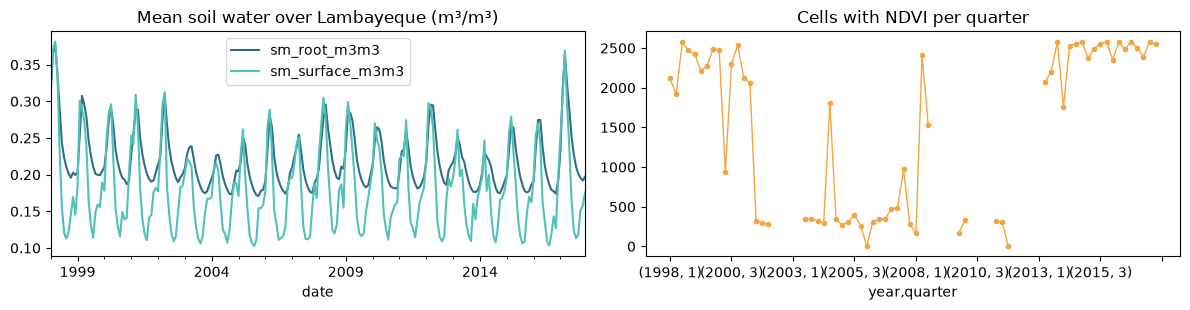

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
monthly.groupby("date")[["sm_root_m3m3", "sm_surface_m3m3"]].mean().plot(ax=ax[0], color=["#2E6E86", "#4FC1B6"])
ax[0].set_title("Mean soil water over Lambayeque (m³/m³)")
cov.stack().plot(ax=ax[1], marker="o", ms=3, color="#F2A541", lw=1)
ax[1].set_title("Cells with NDVI per quarter"); plt.tight_layout(); plt.show()

## 5. Partitions without leakage

Chronological split, decided before looking at any result. Inside Training, the last two years are an **internal
early-stopping block** (no shuffling: neighbouring 2 km cells share the same ERA5-Land pixel, so a random split would
leak). The formal Validation and Testing years are never loaded by this notebook.

In [13]:
print("SPLITS:", SPLITS); print("INTERNAL (inside Training):", INTERNAL)
assert monthly.date.dt.year.between(*YEARS).all() and veg.year.between(*YEARS).all()

SPLITS: {'training': (1998, 2017), 'validation': (2018, 2022), 'testing': (2023, 2026)}
INTERNAL (inside Training): {'fit': (1998, 2015), 'early_stopping': (2016, 2017)}


## 6. Training tables (cells, monthly panel, quarterly panel)

In [14]:
cells = D.cells_from_ids(monthly.cell_id)
merra = power["power_t2m"].merge(power["power_rh2m"], on=["power_lat", "power_lon", "date"]).merge(power["power_ws2m"], on=["power_lat", "power_lon", "date"])
ceres = power["power_allsky"]
cells = F.static_cells(cells, gaez, merra[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True),
                       ceres[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True))
print("max distance to nearest GAEZ pixel (deg):", round(cells.filter(like="_class_dist_deg").max().max(), 3),
      "| to MERRA-2 point:", round(cells.merra_dist_deg.max(), 3), "| to CERES point:", round(cells.ceres_dist_deg.max(), 3))
# T2M from POWER duplicates ERA5-Land t2m_c at a coarser grid: kept in the table for reference, not a feature.
monthly_panel = F.build_monthly_panel(monthly, cells, merra, ceres)
quarterly_panel = F.build_quarterly_panel(monthly_panel, veg)
print("monthly panel:", monthly_panel.shape, "| quarterly panel:", quarterly_panel.shape,
      "| quarterly rows with NDVI:", int(quarterly_panel.ndvi.notna().sum()))
print("POWER values missing after the join:", monthly_panel[["power_rh2m_pct", "power_ws2m_ms", "power_allsky_mj_m2_day"]].isna().sum().to_dict())
cells.to_parquet(OUT_DATA / "cells_static.parquet", index=False)
monthly_panel.to_parquet(OUT_DATA / "monthly_panel_1998_2017.parquet", index=False, compression="zstd")
quarterly_panel.to_parquet(OUT_DATA / "quarterly_panel_1998_2017.parquet", index=False, compression="zstd")
for f in sorted(OUT_DATA.glob("*.parquet")): print(f.name, round(f.stat().st_size / 1e6, 1), "MB")

max distance to nearest GAEZ pixel (deg): 0.084 | to MERRA-2 point: 0.397 | to CERES point: 0.698


monthly panel: (755760, 41) | quarterly panel: (251920, 24) | quarterly rows with NDVI: 91224
POWER values missing after the join: {'power_rh2m_pct': 0, 'power_ws2m_ms': 0, 'power_allsky_mj_m2_day': 0}


cells_static.parquet 0.3 MB
monthly_panel_1998_2017.parquet 30.3 MB
quarterly_panel_1998_2017.parquet 7.2 MB


## 7. Preprocessing fitted on training data only

- **No imputation, no scaling.** XGBoost learns where to send missing values (start-of-series lags, quarters without an
  image); filling them with a median would invent NDVI that was never seen. Trees do not need scaling.
- **Rows dropped:** only rows whose target is missing (23 coastal cells with no ERA5-Land value; quarters without NDVI).
- **Fitted on training rows:** the climatology baselines and the feature ranges used later to warn about out-of-range inputs.

## 8. XGBoost training

In [15]:
PARAMS = dict(n_estimators=3000, learning_rate=0.05, max_depth=6, min_child_weight=20, subsample=0.8,
              colsample_bytree=0.8, reg_alpha=0.0, reg_lambda=1.0, gamma=0.0, objective="reg:squarederror",
              tree_method="hist", eval_metric="rmse", early_stopping_rounds=100, random_state=SEED, n_jobs=16)
COVERAGES = [0.80, 0.90, 0.95]

def train_phase1(name, df, features, target, unit, clim_keys, season, persistence):
    d = df.dropna(subset=[target]).reset_index(drop=True)
    fit, es = d[d.year.between(*INTERNAL["fit"])], d[d.year.between(*INTERNAL["early_stopping"])]
    t0 = time.time()
    m1 = xgb.XGBRegressor(**PARAMS)
    m1.fit(fit[features], fit[target], eval_set=[(fit[features], fit[target]), (es[features], es[target])], verbose=False)
    best_n = m1.best_iteration + 1
    clim = E.climatology(fit, target, clim_keys, season)
    def persist(x):
        p = x[persistence].to_numpy(float)
        return np.where(np.isnan(p), E.predict_climatology(clim, x), p)
    rows = []
    for subset, x in [("fit 1998-2015 (in-sample)", fit), ("internal ES 2016-2017", es)]:
        y = x[target]
        for model, p in [("XGBoost", m1.predict(x[features])), ("baseline: training mean", np.full(len(x), fit[target].mean())),
                         ("baseline: climatology", E.predict_climatology(clim, x)), ("baseline: persistence", persist(x))]:
            rows.append({"subset": subset, "model": model, **E.regression_metrics(y, p)})
    metrics = pd.DataFrame(rows)
    es_rmse = metrics[metrics.subset.str.startswith("internal")].set_index("model").RMSE
    skills = {f"vs {b.split(': ')[1]}": E.skill(es_rmse["XGBoost"], es_rmse[b]) for b in es_rmse.index if b != "XGBoost"}
    # per-year view of the internal block
    p_es = m1.predict(es[features]); res = p_es - es[target].to_numpy()
    per_year = pd.DataFrame([{"year": yr, **E.regression_metrics(es[target][es.year == yr], p_es[es.year == yr])} for yr in sorted(es.year.unique())])
    # provisional split-conformal intervals from the internal block, and an honest check: calibrate on 2016, test on 2017
    halfw = {f"{int(c*100)}%": E.conformal_halfwidth(res, c) for c in COVERAGES}
    cal, chk = (es.year == 2016).to_numpy(), (es.year == 2017).to_numpy()
    check = {f"{int(c*100)}%": float((np.abs(res[chk]) <= E.conformal_halfwidth(res[cal], c)).mean()) for c in COVERAGES}
    # stage 2: refit on all of Training with the number of trees found above
    p2 = {k: v for k, v in PARAMS.items() if k != "early_stopping_rounds"} | {"n_estimators": best_n}
    m2 = xgb.XGBRegressor(**p2).fit(d[features], d[target], verbose=False)
    clim_all = E.climatology(d, target, clim_keys, season)
    insample_all = E.regression_metrics(d[target], m2.predict(d[features]))
    gain = pd.Series(m2.get_booster().get_score(importance_type="gain")).reindex(features).fillna(0)
    sample = d.sample(min(20000, len(d)), random_state=SEED)
    contrib = m2.get_booster().predict(xgb.DMatrix(sample[features]), pred_contribs=True)[:, :-1]
    importance = pd.DataFrame({"gain": gain / gain.sum(), "mean_abs_contribution": np.abs(contrib).mean(0)}, index=features)
    return dict(name=name, target=target, unit=unit, features=features, rows=d, fit=fit, es=es, m1=m1, m2=m2, best_n=best_n,
                params_stage1=PARAMS, params_stage2=p2, metrics=metrics, skills=skills, per_year=per_year, halfw=halfw,
                conformal_check_2016_to_2017=check, insample_all=insample_all, clim=clim_all, importance=importance,
                bounds=E.feature_bounds(d[features]), seconds=round(time.time() - t0, 1))

R = {}
R["sm_root"] = train_phase1("sm_root_monthly", monthly_panel, F.SM_FEATURES, F.SM_TARGET, "m3/m3",
                            ["cell_id", "month"], "month", "sm_root_m3m3_lag1")
print("soil water model: best trees", R["sm_root"]["best_n"], "|", R["sm_root"]["seconds"], "s")
R["ndvi"] = train_phase1("ndvi_quarterly", quarterly_panel, F.NDVI_FEATURES, F.NDVI_TARGET, "index",
                         ["cell_id", "quarter"], "quarter", "ndvi_lag1")
print("NDVI model: best trees", R["ndvi"]["best_n"], "|", R["ndvi"]["seconds"], "s")

soil water model: best trees 1122 | 59.8 s


NDVI model: best trees 89 | 1.4 s


## 9. Training metrics and internal diagnostics

**Internal diagnostics only — not validation or test performance.**

In [16]:
for k, r in R.items():
    print(f"\n=== {r['name']} · target {r['target']} ({r['unit']}) · rows {len(r['rows'])} (fit {len(r['fit'])}, internal ES {len(r['es'])}) · trees {r['best_n']}")
    display(r["metrics"].round(4))
    print("RMSE skill on the internal block:", {a: round(b, 3) for a, b in r["skills"].items()})
    display(r["per_year"].round(4))
    print("Provisional interval half-widths (pooled 2016-2017):", {a: round(b, 4) for a, b in r["halfw"].items()})
    print("Coverage in 2017 of intervals calibrated on 2016:", {a: round(b, 3) for a, b in r["conformal_check_2016_to_2017"].items()})
    print("Refit on all 1998-2017 (in-sample):", {a: round(b, 4) if isinstance(b, float) else b for a, b in r["insample_all"].items()})


=== sm_root_monthly · target sm_root_m3m3 (m3/m3) · rows 750240 (fit 675216, internal ES 75024) · trees 1122


,subset,model,n,MAE,RMSE,R2,bias
0,fit 1998-2015 (in-sample),XGBoost,675216,0.0040,0.0066,0.9960,-0.0000
1,fit 1998-2015 (in-sample),baseline: training mean,675216,0.0871,0.1035,0.0000,0.0000
2,fit 1998-2015 (in-sample),baseline: climatology,675216,0.0211,0.0328,0.8999,0.0000
3,fit 1998-2015 (in-sample),baseline: persistence,675216,0.0181,0.0322,0.9035,0.0001
4,internal ES 2016-2017,XGBoost,75024,0.0116,0.0224,0.9550,-0.0027
5,internal ES 2016-2017,baseline: training mean,75024,0.0888,0.1065,-0.0148,-0.0128
6,internal ES 2016-2017,baseline: climatology,75024,0.0265,0.0433,0.8324,-0.0128
7,internal ES 2016-2017,baseline: persistence,75024,0.0254,0.0428,0.8358,-0.0004


RMSE skill on the internal block: {'vs training mean': 0.789, 'vs climatology': 0.482, 'vs persistence': 0.477}


,year,n,MAE,RMSE,R2,bias
0,2016,37512,0.0086,0.0165,0.974,-0.0018
1,2017,37512,0.0147,0.0271,0.934,-0.0036


Provisional interval half-widths (pooled 2016-2017): {'80%': 0.0164, '90%': 0.0314, '95%': 0.05}
Coverage in 2017 of intervals calibrated on 2016: {'80%': 0.691, '90%': 0.807, '95%': 0.886}
Refit on all 1998-2017 (in-sample): {'n': 750240, 'MAE': 0.0043, 'RMSE': 0.0071, 'R2': 0.9954, 'bias': 0.0}

=== ndvi_quarterly · target ndvi (index) · rows 91224 (fit 71208, internal ES 20016) · trees 89


,subset,model,n,MAE,RMSE,R2,bias
0,fit 1998-2015 (in-sample),XGBoost,71208,0.0696,0.0973,0.7396,-0.0000
1,fit 1998-2015 (in-sample),baseline: training mean,71208,0.1577,0.1907,0.0000,0.0000
2,fit 1998-2015 (in-sample),baseline: climatology,71208,0.0785,0.1081,0.6784,-0.0000
3,fit 1998-2015 (in-sample),baseline: persistence,71208,0.1130,0.1653,0.2485,0.0080
4,internal ES 2016-2017,XGBoost,20016,0.1005,0.1452,0.4893,-0.0495
5,internal ES 2016-2017,baseline: training mean,20016,0.1714,0.2125,-0.0933,-0.0621
6,internal ES 2016-2017,baseline: climatology,20016,0.1154,0.1573,0.4008,-0.0714
7,internal ES 2016-2017,baseline: persistence,20016,0.1373,0.1941,0.0877,-0.0087


RMSE skill on the internal block: {'vs training mean': 0.317, 'vs climatology': 0.077, 'vs persistence': 0.252}


,year,n,MAE,RMSE,R2,bias
0,2016,9993,0.0778,0.1167,0.6656,-0.0093
1,2017,10023,0.1231,0.1690,0.2448,-0.0895


Provisional interval half-widths (pooled 2016-2017): {'80%': 0.1631, '90%': 0.2524, '95%': 0.3312}
Coverage in 2017 of intervals calibrated on 2016: {'80%': 0.639, '90%': 0.784, '95%': 0.873}
Refit on all 1998-2017 (in-sample): {'n': 91224, 'MAE': 0.0725, 'RMSE': 0.1008, 'R2': 0.7333, 'bias': -0.0}


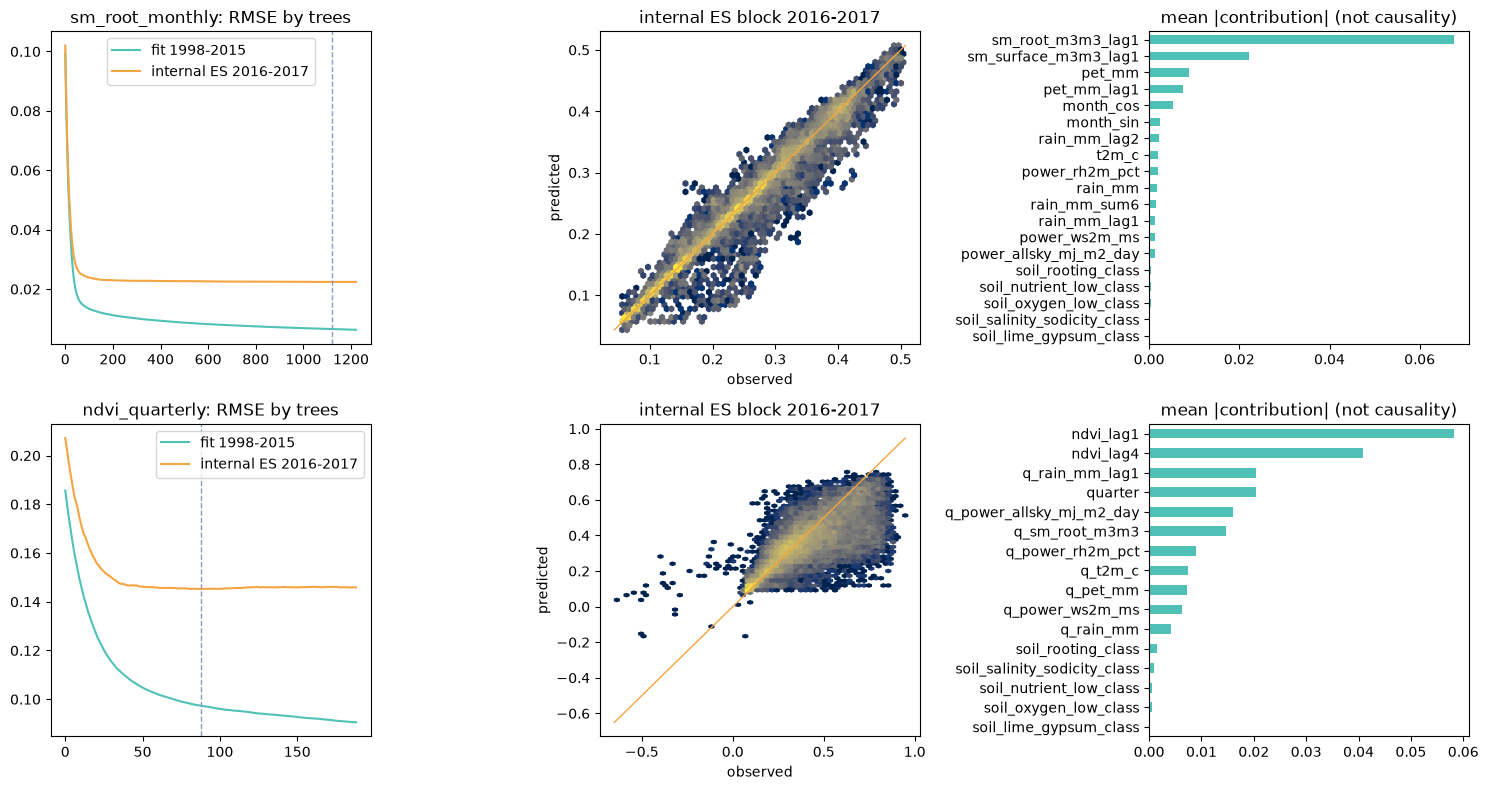

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, (k, r) in zip(axes, R.items()):
    ev = r["m1"].evals_result()
    row[0].plot(ev["validation_0"]["rmse"], color="#4FC1B6", label="fit 1998-2015")
    row[0].plot(ev["validation_1"]["rmse"], color="#F2A541", label="internal ES 2016-2017")
    row[0].axvline(r["best_n"] - 1, color="#8C9BC4", ls="--", lw=1); row[0].set_title(f"{r['name']}: RMSE by trees"); row[0].legend()
    p = r["m1"].predict(r["es"][r["features"]])
    row[1].hexbin(r["es"][r["target"]], p, gridsize=60, bins="log", cmap="cividis")
    lim = [min(r["es"][r["target"]].min(), p.min()), max(r["es"][r["target"]].max(), p.max())]
    row[1].plot(lim, lim, color="#F2A541", lw=1); row[1].set_xlabel("observed"); row[1].set_ylabel("predicted")
    row[1].set_title("internal ES block 2016-2017")
    r["importance"].sort_values("mean_abs_contribution").mean_abs_contribution.plot.barh(ax=row[2], color="#4FC1B6")
    row[2].set_title("mean |contribution| (not causality)")
plt.tight_layout(); fig.savefig(ART / "phase1_diagnostics.png", dpi=110); plt.show()

In [18]:
for k, r in R.items():
    print(r["name"]); display(r["importance"].sort_values("mean_abs_contribution", ascending=False).round(4))

sm_root_monthly


,gain,mean_abs_contribution
sm_root_m3m3_lag1,0.5825,0.0675
sm_surface_m3m3_lag1,0.1859,0.0222
pet_mm,0.0062,0.0089
pet_mm_lag1,0.0053,0.0076
month_cos,0.0351,0.0053
month_sin,0.0200,0.0025
rain_mm_lag2,0.0058,0.0021
t2m_c,0.0060,0.0020
power_rh2m_pct,0.0096,0.0020
rain_mm,0.0092,0.0017


ndvi_quarterly


,gain,mean_abs_contribution
ndvi_lag1,0.2283,0.0582
ndvi_lag4,0.1742,0.0408
q_rain_mm_lag1,0.0958,0.0204
quarter,0.1287,0.0204
q_power_allsky_mj_m2_day,0.0550,0.0161
q_sm_root_m3m3,0.0792,0.0147
q_power_rh2m_pct,0.0332,0.0090
q_t2m_c,0.0387,0.0074
q_pet_mm,0.0312,0.0073
q_power_ws2m_ms,0.0312,0.0062


## 10. Saving models, preprocessing, configuration and metadata

In [19]:
FEATURE_UNITS = {"rain_mm": "mm/month", "rain_mm_lag1": "mm/month", "rain_mm_lag2": "mm/month", "rain_mm_sum6": "mm/6 months",
    "t2m_c": "°C", "pet_mm": "mm/month", "pet_mm_lag1": "mm/month", "sm_root_m3m3_lag1": "m3/m3", "sm_surface_m3m3_lag1": "m3/m3",
    "power_rh2m_pct": "%", "power_ws2m_ms": "m/s", "power_allsky_mj_m2_day": "MJ/m2/day", "month_sin": "-", "month_cos": "-",
    "q_rain_mm": "mm/quarter", "q_rain_mm_lag1": "mm/quarter", "q_t2m_c": "°C", "q_pet_mm": "mm/quarter", "q_sm_root_m3m3": "m3/m3",
    "q_power_rh2m_pct": "%", "q_power_ws2m_ms": "m/s", "q_power_allsky_mj_m2_day": "MJ/m2/day", "quarter": "1-4",
    "ndvi_lag1": "index", "ndvi_lag4": "index", **{s: "FAO GAEZ class code" for s in F.SOIL}}
summary = {}
for k, r in R.items():
    out = ART / r["name"]; out.mkdir(exist_ok=True)
    r["m2"].save_model(out / "model.ubj")
    clim = r["clim"]
    clim["by_cell"].rename("climatology").reset_index().to_parquet(out / "baseline_climatology_by_cell.parquet", index=False)
    clim["by_season"].rename("climatology").reset_index().to_parquet(out / "baseline_climatology_by_season.parquet", index=False)
    preprocessing = {"feature_names_in_order": r["features"], "feature_units": {f: FEATURE_UNITS[f] for f in r["features"]},
                     "missing_values": "left as NaN; XGBoost native handling (no imputer)", "scaling": "none",
                     "training_feature_bounds": r["bounds"], "out_of_range_rule": "warn if any feature < p01 or > p99; strong warning outside min..max",
                     "build_functions": "fs_ml.data + fs_ml.features (same code for every phase)"}
    (out / "preprocessing.json").write_text(json.dumps(preprocessing, indent=2, ensure_ascii=False))
    meta = {
        "phase": "1 - training only", "model": r["name"], "problem_type": "regression", "estimator": "xgboost.XGBRegressor",
        "target": {"column": r["target"], "unit": r["unit"]},
        "features_in_order": r["features"],
        "hyperparameters_stage1_with_early_stopping": r["params_stage1"],
        "hyperparameters_final_refit": r["params_stage2"], "best_number_of_trees": r["best_n"],
        "random_seed": SEED, "library_versions": VERSIONS,
        "data_files": FILES[["key", "file", "sha256"]].to_dict("records"),
        "partitions": {"formal": SPLITS, "internal_inside_training": INTERNAL, "validation_and_testing_used": False},
        "rows": {"training_with_target": len(r["rows"]), "fit": len(r["fit"]), "internal_early_stopping": len(r["es"]),
                 "cells": int(r["rows"].cell_id.nunique())},
        "internal_training_diagnostics": {
            "WARNING": "Internal training diagnostics only. Not validation or test performance.",
            "stage1_metrics": r["metrics"].to_dict("records"), "rmse_skill_internal_block": r["skills"],
            "per_year_internal_block": r["per_year"].to_dict("records"),
            "final_refit_in_sample": r["insample_all"]},
        "provisional_intervals": {"method": "split conformal, absolute residuals of the stage-1 model on 2016-2017",
            "half_width": r["halfw"], "coverage_2017_when_calibrated_on_2016": r["conformal_check_2016_to_2017"],
            "status": "PROVISIONAL - recalibrate on the Validation years before showing any interval to users"},
        "importance_final_model": r["importance"].round(6).to_dict("index"),
        "notes": "Feature importance is not causality. Coordinates, ids and years are not features."}
    (out / "metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str))
    summary[r["name"]] = {"target": r["target"], "unit": r["unit"], "trees": r["best_n"],
        "internal_ES_RMSE": round(float(r["metrics"].query("subset.str.startswith('internal') and model == 'XGBoost'", engine="python").RMSE.iloc[0]), 4),
        "skill": {a: round(b, 3) for a, b in r["skills"].items()}, "interval_90_halfwidth_provisional": round(r["halfw"]["90%"], 4)}
config = {"seed": SEED, "splits": SPLITS, "internal": INTERNAL, "library_versions": VERSIONS, "models": summary,
          "not_trained": {"ndsi_salinidad": "formula undocumented; correlates +0.82 with NDVI",
                          "crop_yield / crop_type / risk classes": "no reference labels"},
          "processed_data": [f.name for f in sorted(OUT_DATA.glob("*.parquet"))]}
(ART / "phase1_summary.json").write_text(json.dumps(config, indent=2, ensure_ascii=False, default=str))
for f in sorted(ART.rglob("*")):
    if f.is_file(): print(f.relative_to(ML_DIR), round(f.stat().st_size / 1e3, 1), "kB")
summary

artifacts/phase1_training/ndvi_quarterly/baseline_climatology_by_cell.parquet 121.0 kB
artifacts/phase1_training/ndvi_quarterly/baseline_climatology_by_season.parquet 1.8 kB
artifacts/phase1_training/ndvi_quarterly/metadata.json 10.9 kB
artifacts/phase1_training/ndvi_quarterly/model.ubj 408.6 kB
artifacts/phase1_training/ndvi_quarterly/preprocessing.json 4.5 kB
artifacts/phase1_training/phase1_diagnostics.png 277.1 kB
artifacts/phase1_training/phase1_summary.json 1.5 kB
artifacts/phase1_training/sm_root_monthly/baseline_climatology_by_cell.parquet 119.9 kB
artifacts/phase1_training/sm_root_monthly/baseline_climatology_by_season.parquet 1.9 kB
artifacts/phase1_training/sm_root_monthly/metadata.json 11.3 kB
artifacts/phase1_training/sm_root_monthly/model.ubj 5104.1 kB
artifacts/phase1_training/sm_root_monthly/preprocessing.json 5.1 kB


{'sm_root_monthly': {'target': 'sm_root_m3m3',
  'unit': 'm3/m3',
  'trees': 1122,
  'internal_ES_RMSE': 0.0224,
  'skill': {'vs training mean': 0.789,
   'vs climatology': 0.482,
   'vs persistence': 0.477},
  'interval_90_halfwidth_provisional': 0.0314},
 'ndvi_quarterly': {'target': 'ndvi',
  'unit': 'index',
  'trees': 89,
  'internal_ES_RMSE': 0.1452,
  'skill': {'vs training mean': 0.317,
   'vs climatology': 0.077,
   'vs persistence': 0.252},
  'interval_90_halfwidth_provisional': 0.2524}}

**Training stops here.** Next phase (Validation 2018–2022): load the reserved years with the same `fs_ml` functions,
predict with `model.ubj` in the saved feature order, compare with the saved baselines, recalibrate the intervals and apply
the acceptance criteria written in `docs/ML_PHASE1_TRAINING.md` before any change to the models.